### 02. Clinical Classification & Statistical Validation

This notebook evaluates the clinical validity of the EF estimation pipeline
across diagnostically relevant categories, comparing heuristic and
corrected predictions. Confusion matrices, ROC curves, AUC, and Cohen's
Kappa are computed as a baseline analysis, extended with bootstrap
confidence intervals and DeLong significance testing to formally assess
whether the learned correction provides a statistically meaningful
improvement.

All analyses in this notebook are performed on the TEST split only,
since it is the only subset untouched by both model training and the
outlier-filtering step, providing an unbiased estimate of real-world
performance.

- **Inputs:** `data/processed/inference_with_corrections.csv`
- **Outputs:** confusion matrices, ROC curves, and a summary statistics table
saved to `figures/`.

In [1]:
import pandas as pd
import numpy as np
from src.stats_utils import classification_metrics_by_class

data = pd.read_csv("../data/processed/inference_with_corrections.csv")
test = data[ data['split'] == 'TEST'].copy()

#### Clinical EF categories

EF thresholds used in clinical cardiology to distinguish principal
categories of ventricular function and associated pathologies:

- **Heart Failure with Reduced Ejection Fraction (HFrEF)**: LVEF ≤40%.
- **Heart Failure with Mid-Range Ejection Fraction (HFmrEF)**: LVEF 41–49%.
- **Heart Failure with Preserved Ejection Fraction (HFpEF)**: LVEF ≥50%.
  (Note: a clinical diagnosis of HFpEF also requires symptoms/signs of heart failure.)
- **Heart Failure with Improved Ejection Fraction (HFimpEF)**: defined as a
  previous LVEF ≤40% that has improved to >40%. (Note: clinical diagnosis needed.)
- **Normal Ejection Fraction**: typically 50–70%. Some sources provide
  slightly more precise ranges, such as 52–72% for males and 54–74% for females.
- **Hypertrophic Cardiomyopathy (HCM)**: characterized by unexplained left
  ventricular hypertrophy with a preserved or even increased ejection
  fraction, often above the normal range (≥75%).

Since both HFpEF and HFimpEF require additional clinical assessment beyond
imaging-derived EF values alone, further analysis is restricted to the
remaining categories: **HFrEF, HFmrEF, Normal EF, and HCM** — consistent
with the scope of the original (unpublished) classification analysis.

In [2]:
def classify_ef(ef):
    if ef <= 40:
        return 'HFrEF'
    elif ef < 50:
        return 'HFmrEF'
    elif ef < 75:
        return 'Normal'
    else:
        return 'HCM'

test['true_class'] = test['true_ef'].apply(classify_ef)
test['heuristic_class'] = test['predicted_ef'].apply(classify_ef)
test['corrected_class'] = test['corrected_ef'].apply(classify_ef)

#### Confusion Matrices

In [3]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = ['HFrEF', 'HFmrEF', 'Normal', 'HCM']
cm_heuristic = confusion_matrix(test['true_class'], test['heuristic_class'], labels=labels)
cm_corrected = confusion_matrix(test['true_class'], test['corrected_class'], labels=labels)

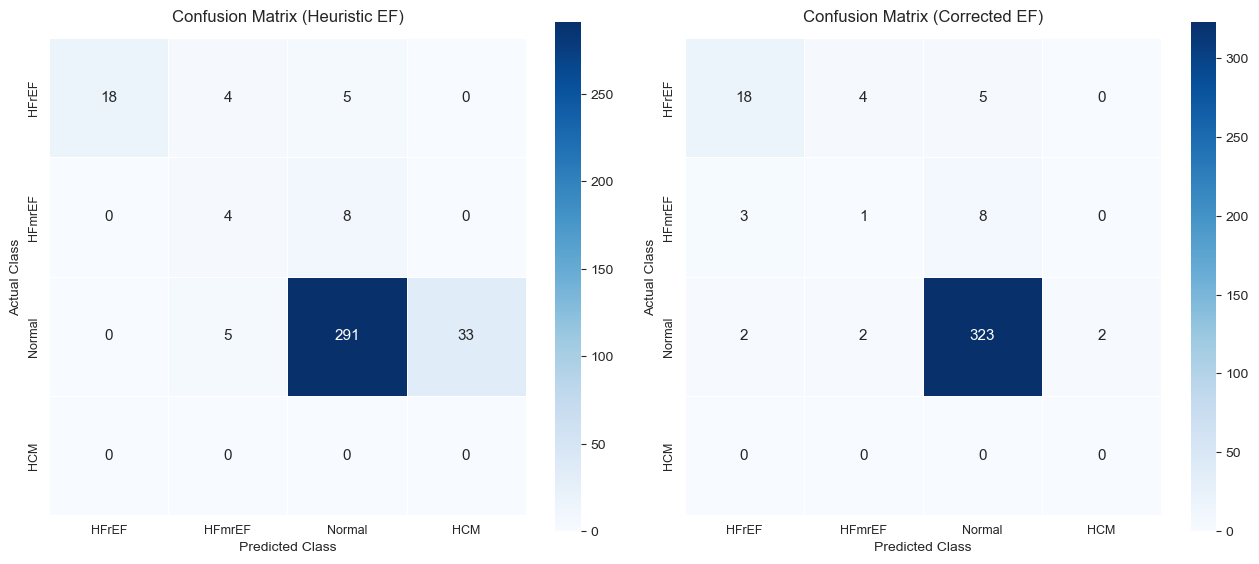

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, cm, title in zip(
    axes,
    [cm_heuristic, cm_corrected],
    ['Confusion Matrix (Heuristic EF)', 'Confusion Matrix (Corrected EF)']
):
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=labels, yticklabels=labels,
        cbar=True, square=True, linewidths=0.5, linecolor='white',
        annot_kws={"size": 11}, ax=ax
    )
    ax.set_title(title, fontsize=12, pad=12)
    ax.set_xlabel('Predicted Class', fontsize=10)
    ax.set_ylabel('Actual Class', fontsize=10)
    ax.tick_params(axis='both', labelsize=9)

plt.tight_layout()
plt.savefig('../figures/confusion_matrices.png', dpi=200, bbox_inches='tight')
plt.show()

"Hypertrophic CM" in both the "Heuristic EF" and "Corrected EF" confusion matrices, has all values in zero. This indicates that the test dataset contains no true positive cases for this category (no patients with EF > 75%).

In [5]:
count = 0

for ef in test['true_ef']:
    if ef >= 75:
        count += 1
count

0

#### Per-class classification metrics

Sensitivity, specificity, precision, and F1-score are calculated
for each EF category to provide a detailed assessment of
classification performance.

Macro-F1 and Weighted-F1 are also reported as complementary
summary metrics. Macro-F1 assigns equal weight to each represented
category, whereas Weighted-F1 accounts for the number of samples
in each category.

In [6]:
labels = ['HFrEF', 'HFmrEF', 'Normal', 'HCM']

heuristic_metrics = classification_metrics_by_class(
    test['true_class'],
    test['heuristic_class'],
    labels
)
heuristic_metrics.insert(0, 'Model', 'Heuristic')

corrected_metrics = classification_metrics_by_class(
    test['true_class'],
    test['corrected_class'],
    labels
)
corrected_metrics.insert(0, 'Model', 'Corrected')

classification_metrics = pd.concat(
    [heuristic_metrics, corrected_metrics],
    ignore_index=True
)

display(classification_metrics.round(3))

,Model,Category,Sensitivity,Specificity,Precision,F1-score,Support
0,Heuristic,HFrEF,0.667,1.000,1.000,0.800,27
1,Heuristic,HFmrEF,0.333,0.975,0.308,0.320,12
2,Heuristic,Normal,0.884,0.667,0.957,0.919,329
3,Heuristic,HCM,NaN,0.910,0.000,0.000,0
4,Corrected,HFrEF,0.667,0.985,0.783,0.720,27
5,Corrected,HFmrEF,0.083,0.983,0.143,0.105,12
6,Corrected,Normal,0.982,0.667,0.961,0.971,329
7,Corrected,HCM,NaN,0.995,0.000,0.000,0


In [7]:
macro_f1 = (
    classification_metrics[
        classification_metrics['Support'] > 0
    ]
    .groupby('Model')['F1-score']
    .mean()
    .rename('Macro-F1')
    .reset_index()
)

display(macro_f1.round(3))

,Model,Macro-F1
0,Corrected,0.599
1,Heuristic,0.680


In [13]:
weighted_f1 = (
    classification_metrics[classification_metrics['Support'] > 0]
    .assign(
        weighted_f1=lambda x: x['F1-score'] * x['Support']
    )
    .groupby('Model')
    .agg(
        weighted_sum=('weighted_f1', 'sum'),
        total_support=('Support', 'sum')
    )
)

weighted_f1['Weighted-F1'] = (
    weighted_f1['weighted_sum'] / weighted_f1['total_support']
)

display(weighted_f1[['Weighted-F1']].round(3))

,Weighted-F1
Model,
Corrected,0.925
Heuristic,0.891


#### Classification performance

The corrected model shows different effects across EF categories.

- **HFrEF:** Sensitivity remains unchanged (0.667), while precision and F1-score decrease.
- **HFmrEF:** Classification performance declines, with sensitivity decreasing from 0.333 to 0.083 and F1-score from 0.320 to 0.105.
- **Normal EF:** Performance improves, with sensitivity increasing from 0.884 to 0.982 and F1-score from 0.919 to 0.971.
- **HCM:** No true cases are present in the test set, preventing sensitivity evaluation.

The Weighted-F1 increases from 0.891 to 0.925, indicating improved classification performance when accounting for the category distribution in the test set. In contrast, Macro-F1 decreases from 0.680 to 0.599, reflecting the reduced performance in HFmrEF when all represented categories contribute equally.

Overall, the correction improves performance for the predominant Normal EF category and increases the weighted classification score, although its benefits are not uniform across categories.

#### ROC curves by clinical category

Binary classification performance for HFrEF (≤40%), HFmrEF (41–49%), and
Normal EF (50–74%), comparing heuristic and corrected predictions.

Since these are threshold-based tasks derived from a continuous regression
output, the following scores are used as decision functions:
- **HFrEF**: negative EF (lower EF → higher HFrEF likelihood)
- **HFmrEF**: negative distance to the range midpoint (45%)
- **Normal**: negative distance to the range midpoint (62.5%)

AUC values are reported with bootstrap 95% confidence intervals.

In [8]:
from sklearn.metrics import roc_curve, roc_auc_score
from src.stats_utils import bootstrap_auc_ci

# Define binary tasks (true_label, heuristic_score, corrected_score)
tasks = {
    'HFrEF vs. Non-HFrEF (EF ≤40%)': {
        'y_true': (test['true_ef'] <= 40).astype(int),
        'score_heuristic': -test['predicted_ef'],
        'score_corrected': -test['corrected_ef'],
    },
    'HFmrEF vs Non-HFmrEF (EF 41-49%)': {
        'y_true': ((test['true_ef'] > 40) & (test['true_ef'] < 50)).astype(int),
        'score_heuristic': -np.abs(test['predicted_ef'] - 45),
        'score_corrected': -np.abs(test['corrected_ef'] - 45),
    },
    'Normal EF vs Abnormal (EF 50-<75%)': {
        'y_true': ((test['true_ef'] >= 50) & (test['true_ef'] < 75)).astype(int),
        'score_heuristic': -np.abs(test['predicted_ef'] - 62.5),
        'score_corrected': -np.abs(test['corrected_ef'] - 62.5),
    },
}

#### Visualization

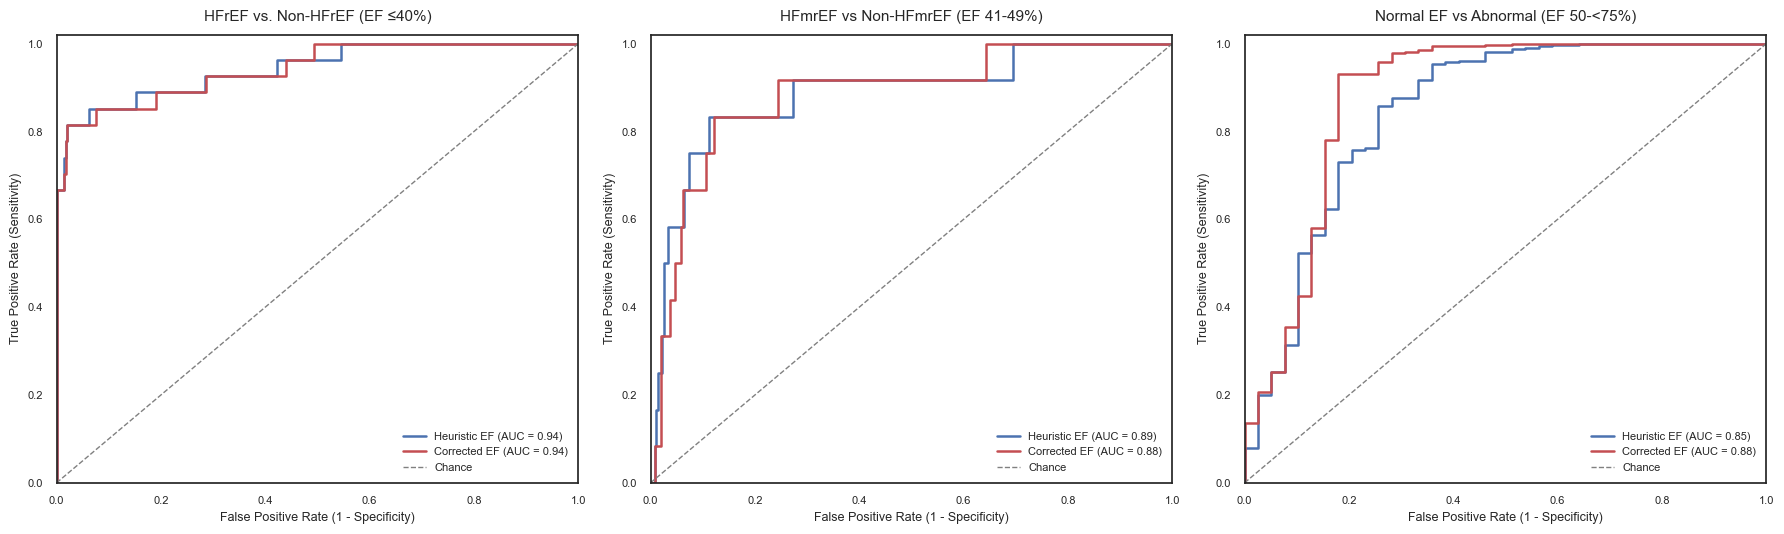

,AUC (Heuristic),CI (Heuristic),AUC (Corrected),CI (Corrected)
HFrEF vs. Non-HFrEF (EF ≤40%),0.943195,"(0.886, 0.989)",0.942326,"(0.886, 0.987)"
HFmrEF vs Non-HFmrEF (EF 41-49%),0.886938,"(0.753, 0.972)",0.884363,"(0.765, 0.963)"
Normal EF vs Abnormal (EF 50-<75%),0.84857,"(0.769, 0.922)",0.882082,"(0.803, 0.953)"


In [9]:
sns.set_theme(style="white", font_scale=1.0)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

results = {}

for ax, (task_name, t) in zip(axes, tasks.items()):
    fpr_h, tpr_h, _ = roc_curve(t['y_true'], t['score_heuristic'])
    fpr_c, tpr_c, _ = roc_curve(t['y_true'], t['score_corrected'])

    auc_h = roc_auc_score(t['y_true'], t['score_heuristic'])
    auc_c = roc_auc_score(t['y_true'], t['score_corrected'])

    ci_h, _ = bootstrap_auc_ci(t['y_true'], t['score_heuristic'])
    ci_c, _ = bootstrap_auc_ci(t['y_true'], t['score_corrected'])

    results[task_name] = {
        'AUC (Heuristic)': auc_h, 'CI (Heuristic)': tuple(np.round(ci_h, 3)),
        'AUC (Corrected)': auc_c, 'CI (Corrected)': tuple(np.round(ci_c, 3)),
    }

    ax.plot(fpr_h, tpr_h, color='#4C72B0', lw=1.8, label=f'Heuristic EF (AUC = {auc_h:.2f})')
    ax.plot(fpr_c, tpr_c, color='#C44E52', lw=1.8, label=f'Corrected EF (AUC = {auc_c:.2f})')
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray', lw=1, label='Chance')

    ax.set_title(task_name, fontsize=11, pad=10)
    ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=9)
    ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=9)
    ax.tick_params(labelsize=8)
    ax.legend(loc='lower right', fontsize=8, frameon=False)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.02])

plt.tight_layout()
plt.savefig('../figures/roc_curves.png', dpi=200, bbox_inches='tight')
plt.show()

pd.DataFrame(results).T

AUC remains stable for HFrEF (0.94) and HFmrEF (~0.87-0.88), while Normal
EF shows the clearest improvement with correction (0.84 → 0.87), visible in
the tighter curve at low false-positive rates.

#### DeLong test

Since both AUCs are computed on the same TEST set, they are correlated and
cannot be compared with an independent-samples test. The DeLong test
accounts for this correlation.

For each category:
- H0: AUC_corrected = AUC_heuristic
- H1: AUC_corrected > AUC_heuristic (one-tailed, since the correction is
  expected to improve or maintain discrimination)
- alpha = 0.05

In [10]:
from src.stats_utils import delong_test

for task_name, t in tasks.items():
    z, p, auc_h, auc_c = delong_test(t['y_true'], t['score_heuristic'], t['score_corrected'])
    decision = "reject H0" if p < 0.05 else "fail to reject H0"
    print(f"{task_name}")
    print(f"  AUC heuristic={auc_h:.3f}  AUC corrected={auc_c:.3f}  z={z:.3f}  p={p:.4f}  -> {decision}")

HFrEF vs. Non-HFrEF (EF ≤40%)
  AUC heuristic=0.943  AUC corrected=0.942  z=-0.319  p=0.6251  -> fail to reject H0
HFmrEF vs Non-HFmrEF (EF 41-49%)
  AUC heuristic=0.887  AUC corrected=0.884  z=-0.250  p=0.5988  -> fail to reject H0
Normal EF vs Abnormal (EF 50-<75%)
  AUC heuristic=0.849  AUC corrected=0.882  z=2.891  p=0.0019  -> reject H0


#### Multiple-comparison correction

The p-values from the three DeLong tests are adjusted using the
Holm procedure to control the family-wise error rate across the
category-level comparisons.

Statistical significance is assessed using the adjusted p-values
and a significance level of 0.05.

In [12]:
from statsmodels.stats.multitest import multipletests

delong_rows = []

for task_name, task in tasks.items():
    z, p_value, auc_heuristic, auc_corrected = delong_test(
        task['y_true'],
        task['score_heuristic'],
        task['score_corrected']
    )

    delong_rows.append({
        'Category': task_name,
        'AUC heuristic': auc_heuristic,
        'AUC corrected': auc_corrected,
        'AUC difference': auc_corrected - auc_heuristic,
        'z': z,
        'p-value': p_value
    })

delong_results = pd.DataFrame(delong_rows)

reject, p_adjusted, _, _ = multipletests(
    delong_results['p-value'],
    alpha=0.05,
    method='holm'
)

delong_results['p-value (Holm)'] = p_adjusted
delong_results['Significant after Holm'] = reject

display(delong_results.round(4))

,Category,AUC heuristic,AUC corrected,AUC difference,z,p-value,p-value (Holm),Significant after Holm
0,HFrEF vs. Non-HFrEF (EF ≤40%),0.9432,0.9423,-0.0009,-0.3190,0.6251,1.0000,False
1,HFmrEF vs Non-HFmrEF (EF 41-49%),0.8869,0.8844,-0.0026,-0.2502,0.5988,1.0000,False
2,Normal EF vs Abnormal (EF 50-<75%),0.8486,0.8821,0.0335,2.8913,0.0019,0.0058,True


#### DeLong test results

After Holm correction for multiple comparisons, the corrected
model shows a statistically significant improvement in
discrimination for Normal EF (AUC: 0.8486 to 0.8821;
adjusted p = 0.0058).

For HFrEF and HFmrEF, the differences between the heuristic
and corrected AUCs are small and do not reach statistical
significance after correction.

These findings indicate that the improvement in discrimination
is specific to Normal EF in this evaluation. The absence of
statistical significance in the other categories does not
establish equivalence between the two approaches.

#### Cohen's Kappa

Cohen's Kappa measures agreement between predicted and true clinical
categories, correcting for the agreement expected by chance given the
class distribution. This is particularly important here since the dataset
is heavily imbalanced toward Normal EF, which would inflate simple
accuracy without reflecting real diagnostic agreement.

The heuristic and corrected Kappa values are compared using a paired
bootstrap on their difference, following
the same rationale as the DeLong test:

- H0: kappa_corrected - kappa_heuristic = 0
- H1: kappa_corrected - kappa_heuristic > 0 (one-tailed)
- alpha = 0.05

In [15]:
from sklearn.metrics import cohen_kappa_score
from src.stats_utils import bootstrap_kappa_diff

diffs, ci, n_valid = bootstrap_kappa_diff(
    test['true_class'],
    test['heuristic_class'],
    test['corrected_class']
)

kappa_heuristic = cohen_kappa_score(
    test['true_class'],
    test['heuristic_class']
)

kappa_corrected = cohen_kappa_score(
    test['true_class'],
    test['corrected_class']
)

kappa_diff = kappa_corrected - kappa_heuristic

print(f"Heuristic Kappa: {kappa_heuristic:.3f}")
print(f"Corrected Kappa: {kappa_corrected:.3f}")
print(f"Kappa difference: {kappa_diff:.3f}")
print(f"95% CI: [{ci[0]:.3f}, {ci[1]:.3f}]")
print(f"Valid bootstrap resamples: {n_valid}")

Heuristic Kappa: 0.418
Corrected Kappa: 0.604
Kappa difference: 0.186
95% CI: [0.102, 0.274]
Valid bootstrap resamples: 0.0


Cohen's Kappa increases from 0.418 for the heuristic estimates
to 0.604 for the corrected estimates, indicating improved
agreement with the reference EF categories.

The paired bootstrap estimates a difference of 0.204,
with a 95% confidence interval of [0.102, 0.274].
Since the interval does not include zero, the results support
an improvement in categorical agreement after correction.

#### Conclusions

The clinical classification analysis shows that the correction model improves overall categorical agreement and weighted classification performance. It also achieves a significant improvement in Normal EF discrimination after Holm correction.

However, the benefits are not uniform across categories. In particular, HFmrEF classification performance decreases, highlighting a remaining limitation of the corrected estimates.

Overall, the results support the value of the correction model while showing that its performance depends on the EF category being evaluated.